In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [52]:
X = 6 * np.random.rand(100, 1) - 3

y = 0.5*(X**2) + 1.5*X + 2 + np.random.randn(100, 1)

In [53]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42)

In [54]:
#Standardization
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [55]:
# Adding Linear Regression

from sklearn.linear_model import LinearRegression
regression = LinearRegression()

regression.fit(X_train, y_train)

print(regression.coef_)
print(regression.intercept_)

[[2.95511653]]
[4.02338567]


In [56]:
y_pred_train = regression.predict(X_train)

y_pred = regression.predict(X_test)

In [57]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, root_mean_squared_error
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)

print(mse)
print(mae)
print(rmse)

2.1869629851668204
1.143194019734596
1.478838390483159


In [58]:
from sklearn.metrics import r2_score
score = r2_score(y_test, y_pred)
print(score)

adj_score = 1 - ((1 - score)*(len(y_test) - 1)/(len(y_test) - X_test.shape[1] - 1))
print(adj_score)

0.7083940318750939
0.6921937003125991


[[0.         3.08542114 1.54215789]]
[2.48122778]
0.8283114557417951
0.7961198536933817


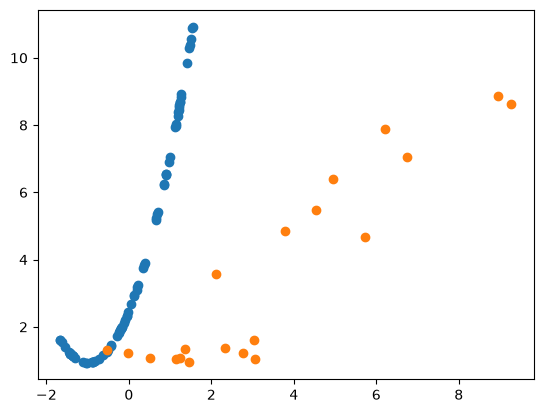

In [59]:
# Adding polynomial regression

from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree =2, include_bias=True)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

# Applying Linear Regression
regression_1 = LinearRegression()
regression_1.fit(X_train_poly, y_train)

y_train_poly_pred = regression_1.predict(X_train_poly)

print(regression_1.coef_)
print(regression_1.intercept_)

y_pred_poly = regression_1.predict(X_test_poly)


from sklearn.metrics import r2_score
score_poly = r2_score(y_test, y_pred_poly)
print(score_poly)

adj_score_poly = 1 - ((1 - score_poly)*(len(y_test) - 1)/(len(y_test) - X_test_poly.shape[1] - 1))
print(adj_score_poly)

plt.scatter(X_train, y_train_poly_pred)
plt.scatter(y_test, y_pred_poly)

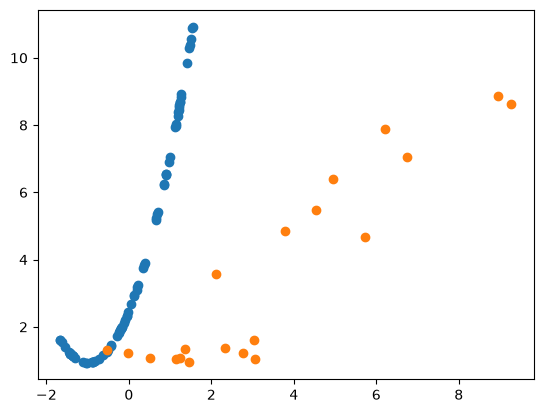

In [60]:
plt.scatter(X_train, y_train_poly_pred)
# plt.scatter(X_train, y_train)

# plt.scatter(X_test,y_test)
plt.scatter(y_test, y_pred_poly)

Pipelines in Polynomials

In [71]:
X_new = np.linspace(-3,3,200).reshape(200,1)
from sklearn.pipeline import Pipeline
def poly_regression(degree):
    poly_features = PolynomialFeatures(degree=degree, include_bias=True)
    lin_reg = LinearRegression()

    poly_reg = Pipeline([("poly_features", poly_features),("lin_reg", lin_reg)])

    poly_reg.fit(X_train, y_train)

    y_pred_new = poly_reg.predict(X_new)

    plt.plot(X_new, y_pred_new)
    plt.scatter(X_train, y_train)
    plt.scatter(X_test, y_test)


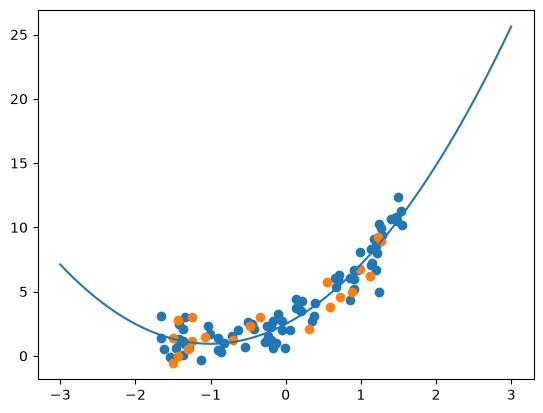

In [72]:
poly_regression(degree=2)